# PPO Navigation

Easy → Medium → Hard. **Run All** displays the saved 23 October 2026 results. Training is off by default.


In [1]:
import json
import logging
import os
from pathlib import Path
import sys

SUBMISSION_DIR = next(
    candidate
    for parent in [Path.cwd(), *Path.cwd().parents]
    for candidate in [parent, parent / "ppo_submission"]
    if (candidate / "PPO_Results.ipynb").is_file()
    and (candidate / "runtime.py").is_file()
)
ROOT = SUBMISSION_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RUN_DIR = SUBMISSION_DIR / "ppo_results"
CACHE_DIR = SUBMISSION_DIR / ".cache"
os.environ.setdefault("MPLCONFIGDIR", str(CACHE_DIR / "matplotlib"))
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
from ppo_submission.notebook_utils import (
    show_figure, show_learning_curves, show_table, train_curriculum,
)
from ppo_submission.plots import STAGES, read_stage, read_history

print("Selected run:", RUN_DIR.relative_to(SUBMISSION_DIR))


Selected run: ppo_results


## Optional training

Set `RUN_TRAINING = True` for a new run; use `RESUME_TRAINING` to continue it. Minimum budgets: **500k / 400k / 300k** steps. Each stage requires two separate 100/100 collision-free evaluation batches.


In [2]:
RUN_TRAINING = False
RESUME_TRAINING = False
TRAIN_DIR = SUBMISSION_DIR / "outputs" / "ppo_curriculum"

if RUN_TRAINING:
    train_curriculum(ROOT, TRAIN_DIR, resume=RESUME_TRAINING)
    RUN_DIR = TRAIN_DIR
else:
    print("Training skipped. Displaying saved results.")


Training skipped. Displaying saved results.


## Stage results

Final screening metrics from the raw evaluation logs. Timesteps are cumulative across stages.


In [3]:
histories = {stage: read_stage(RUN_DIR, stage)[0] for stage, *_ in STAGES}
config = json.loads((RUN_DIR / "run_config.json").read_text())
status = json.loads((RUN_DIR / "status.json").read_text())
print(f"Started: {config['started_at']} | State: {status['state']}")

rows = []
for stage, points in histories.items():
    final = points[-1]
    rows.append([
        stage.title(),
        f"{final['stage_timesteps']:,}",
        f"{final['cumulative_timesteps']:,}",
        f"{final['mean_return']:+.2f}",
        f"{final['mean_episode_length']:.2f}",
        f"{final['success_rate']:.0%}",
        f"{final['collision_rate']:.0%}",
    ])

show_table(
    ["Stage", "Stage steps", "Total steps", "Return", "Length (steps)", "Success", "Collision"],
    rows,
)
print("Evaluation checkpoints:", sum(map(len, histories.values())))


Started: 2026-10-23T13:28:21.984151+11:00 | State: complete


Stage,Stage steps,Total steps,Return,Length (steps),Success,Collision
Easy,"500,000","500,000",+51.87,42.04,100%,0%
Medium,"560,000","1,060,000",+42.73,52.24,100%,0%
Hard,"311,296","1,371,296",+51.27,52.70,100%,0%


Evaluation checkpoints: 74


## Learning curves

Mean ±1 standard deviation across 100 episodes per checkpoint; no smoothing.


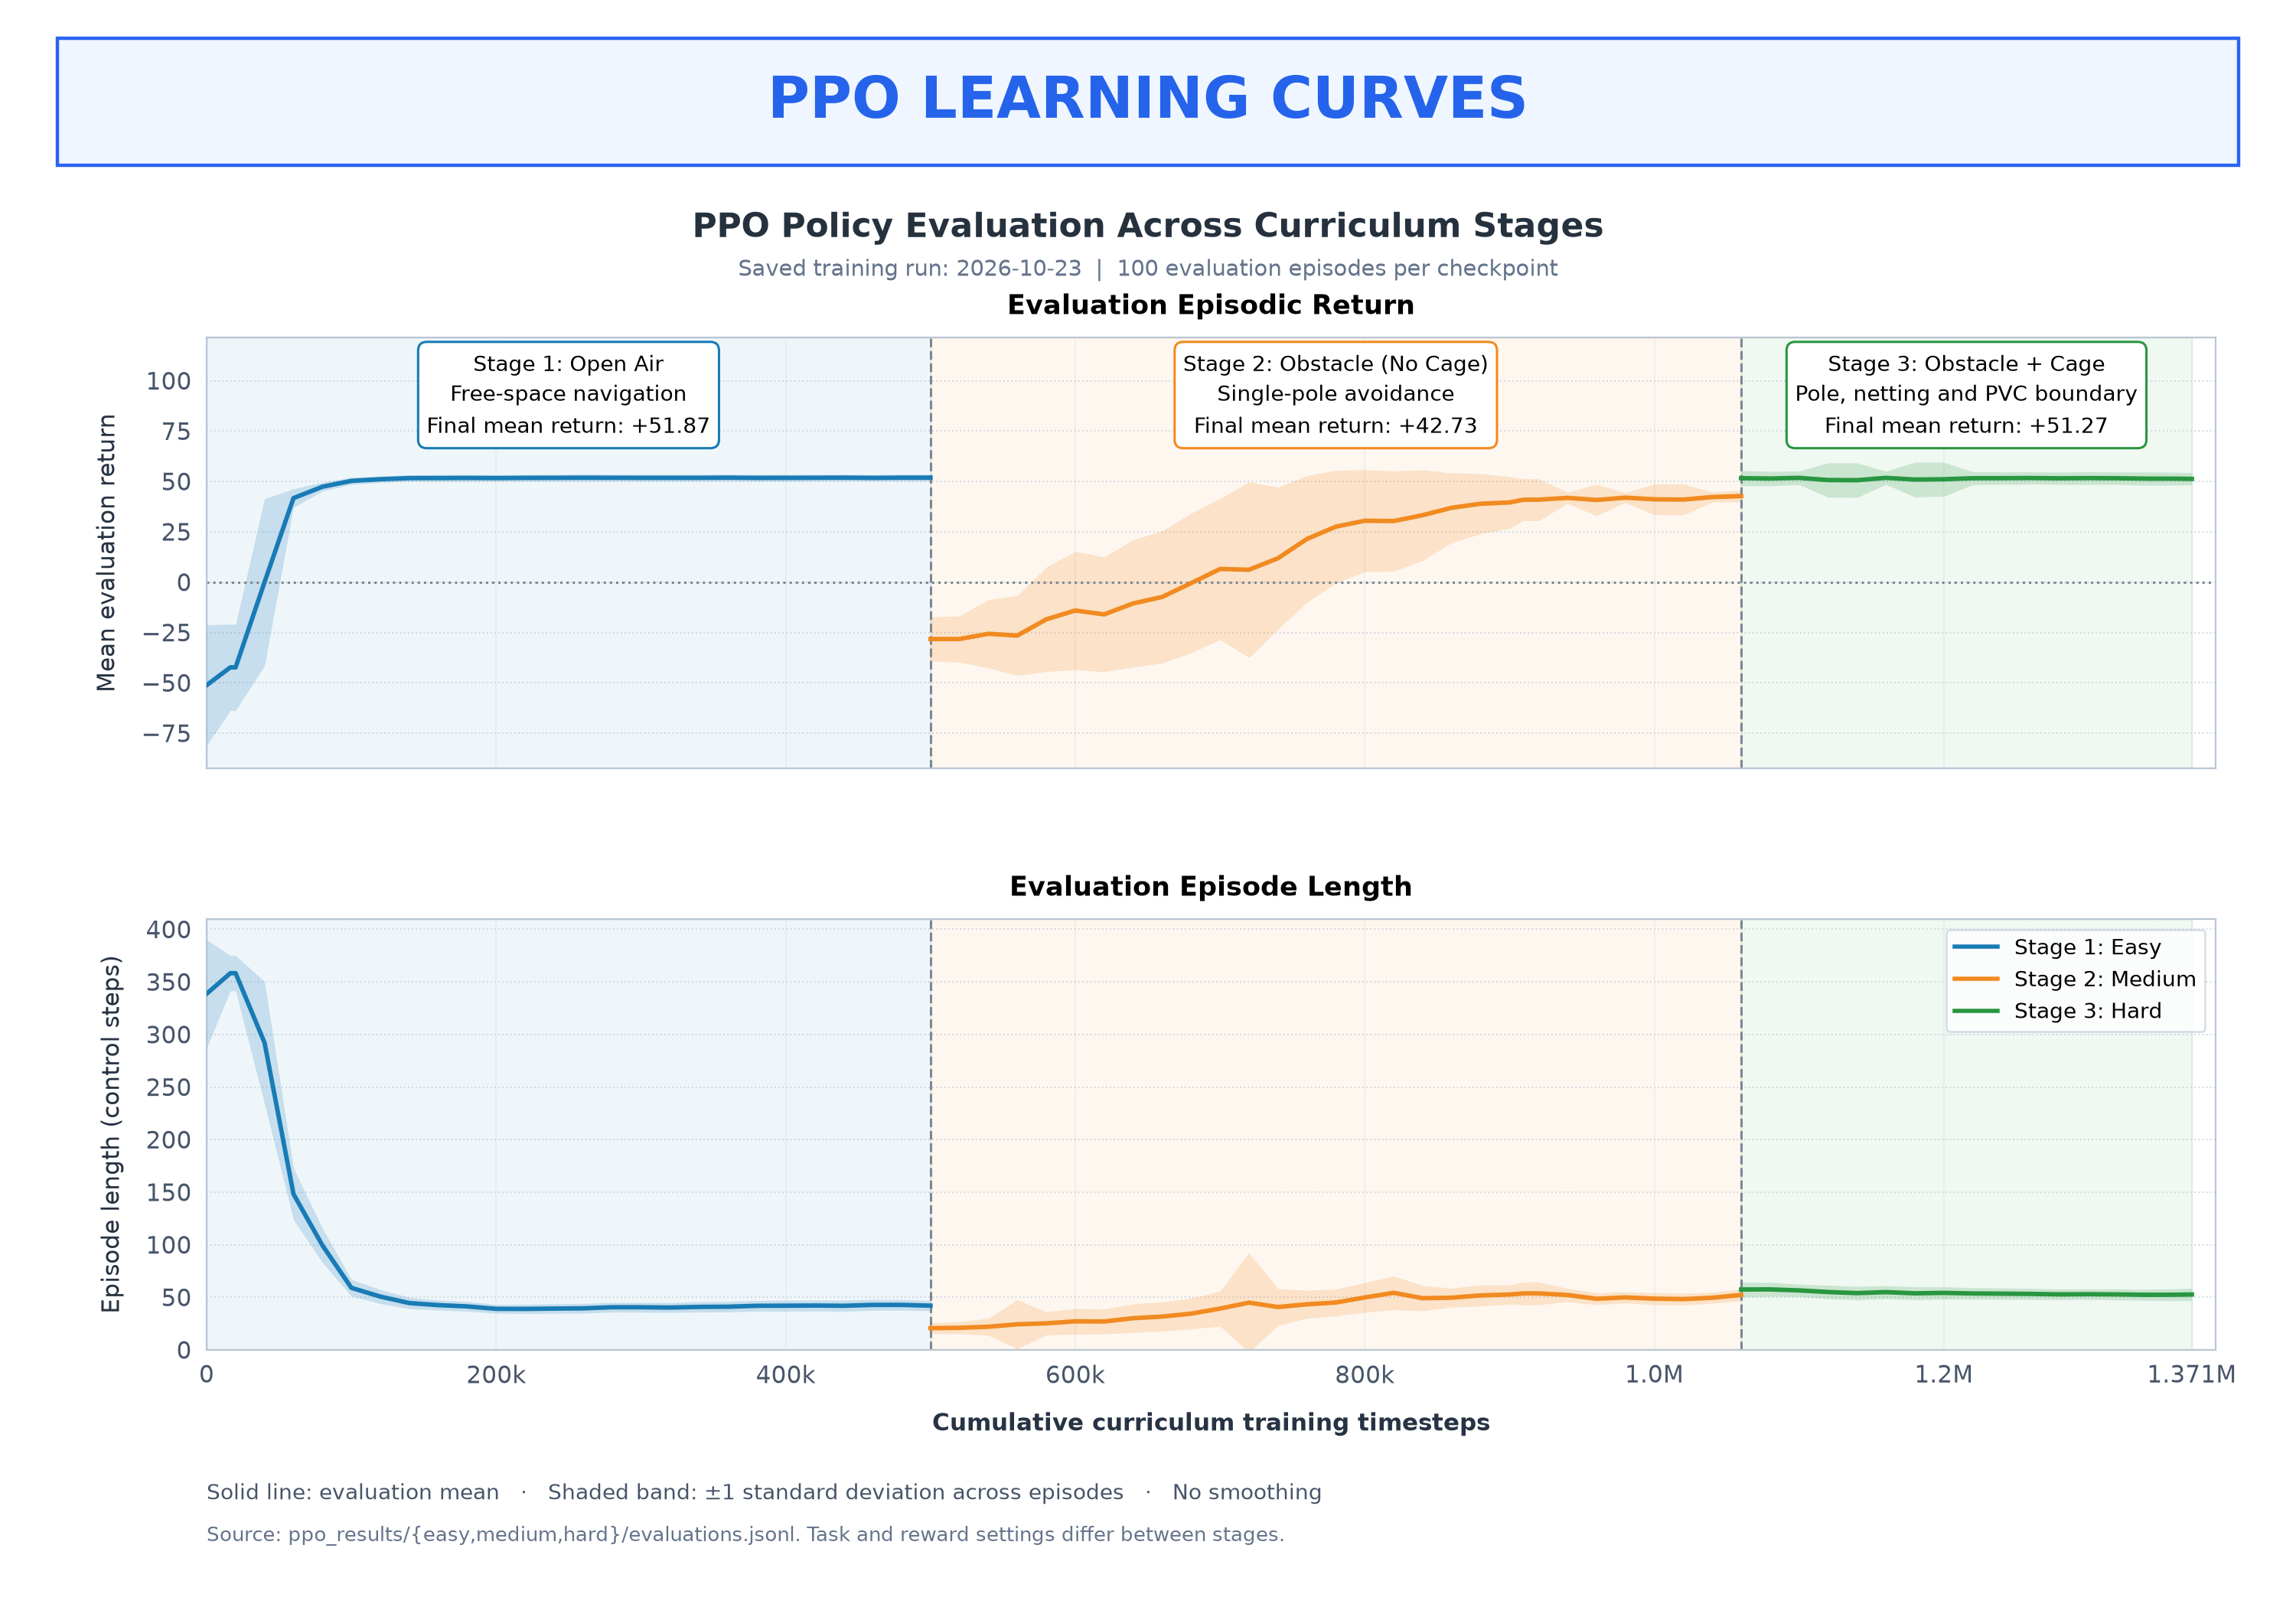

In [4]:
show_learning_curves(RUN_DIR, CACHE_DIR)


## Independent validation

Separate evaluation seeds, including earlier failed attempts. These are saved results; no new episodes run here.


In [5]:
rows = []
for stage in histories:
    directory = RUN_DIR / stage
    paths = [*sorted(directory.glob("validation_attempt_*.json")), directory / "validation.json"]
    for path in paths:
        batch = json.loads(path.read_text())
        episodes = batch["results"]
        assert len(episodes) == batch["episodes"]
        successes = sum(episode["success"] and not episode["collision"] for episode in episodes)
        collisions = sum(episode["collision"] for episode in episodes)
        label = "Final" if path.stem == "validation" else f"Attempt {int(path.stem.rsplit('_', 1)[1])}"
        rows.append([
            stage.title(), label, f"{successes}/{len(episodes)}", collisions,
            f"{np.mean([episode['reward'] for episode in episodes]):+.2f}",
        ])

show_table(["Stage", "Batch", "Success", "Collisions", "Return"], rows)


Stage,Batch,Success,Collisions,Return
Easy,Final,100/100,0,+51.82
Medium,Attempt 1,98/100,2,+40.27
Medium,Attempt 2,99/100,1,+40.89
Medium,Attempt 3,99/100,1,+40.99
Medium,Final,100/100,0,+42.56
Hard,Attempt 1,99/100,1,+50.39
Hard,Final,100/100,0,+51.07


## Critic diagnostics

Dots: logged values, including resumed segments. Lines: trailing five-point means.


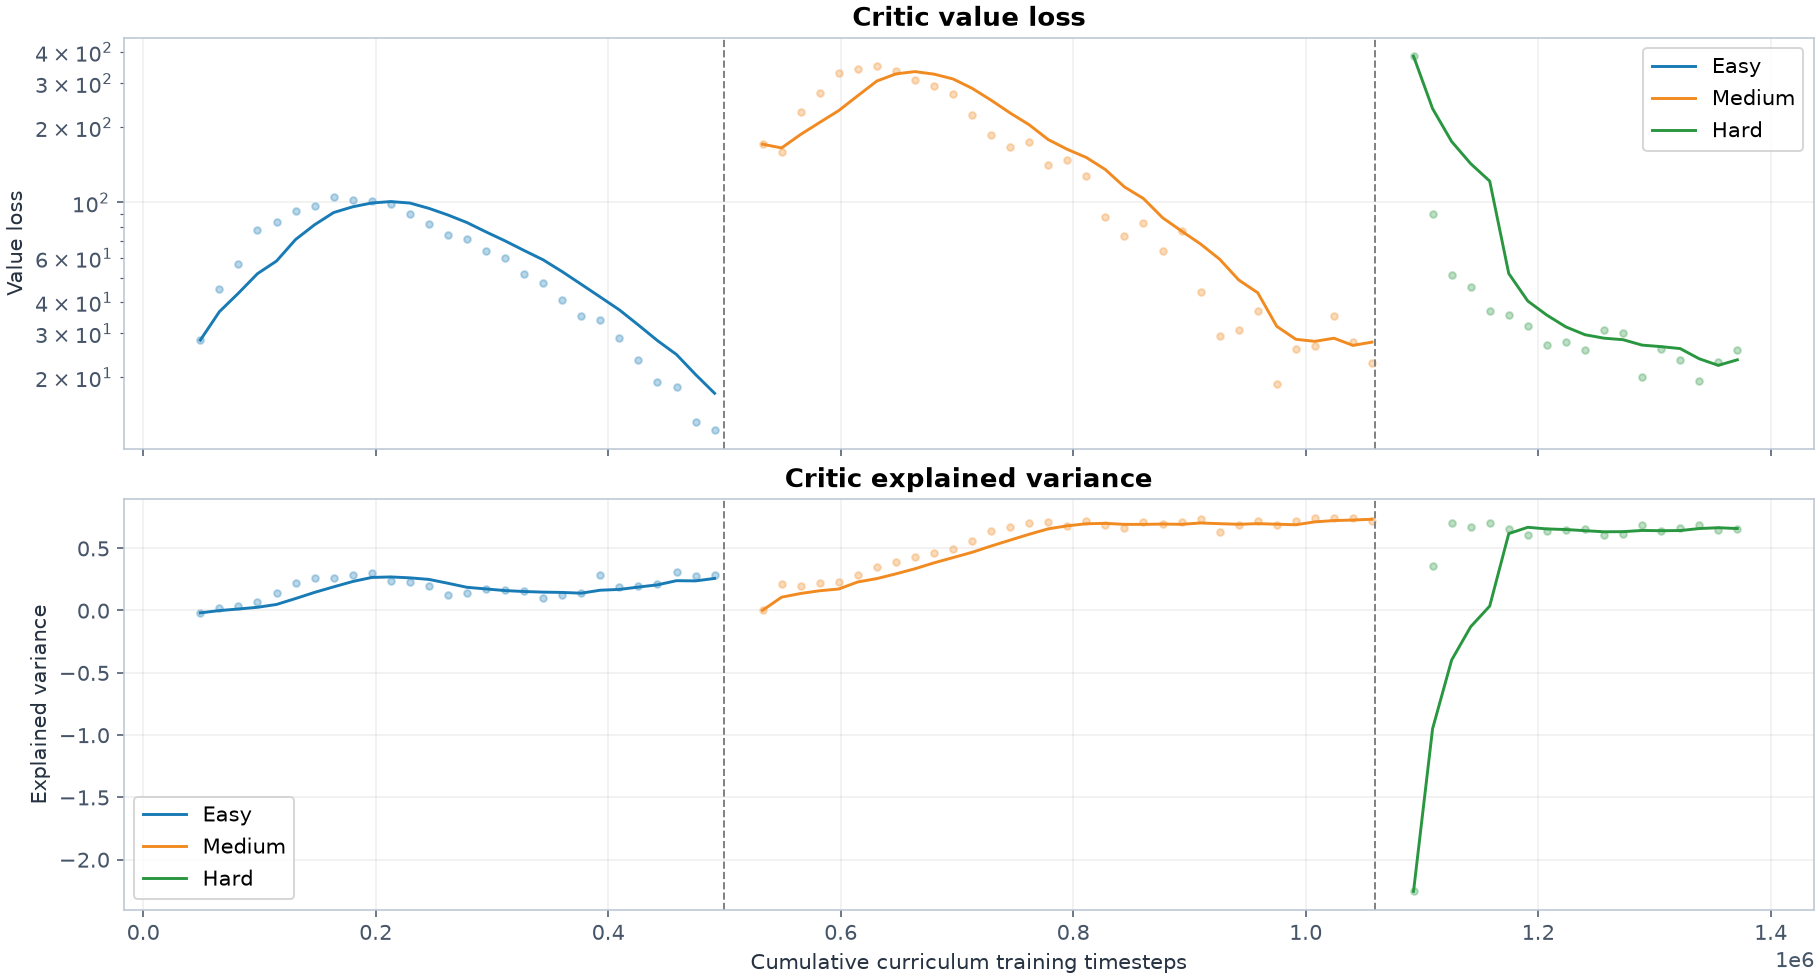

In [6]:
critic = read_history(RUN_DIR, critic=True)
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, layout="constrained")

for stage, _, _, colour in STAGES:
    points = critic[stage]
    timesteps = np.array([point["timesteps"] for point in points])
    for axis, metric in zip(axes, ["first", "second"]):
        values = np.array([point[metric] for point in points])
        rolling_mean = [values[max(0, i - 4):i + 1].mean() for i in range(len(values))]
        axis.scatter(timesteps, values, color=colour, s=12, alpha=.3)
        axis.plot(timesteps, rolling_mean, color=colour, label=stage.title())

for axis in axes:
    axis.grid(alpha=.2)
    axis.legend()
    for stage in list(histories)[1:]:
        boundary = histories[stage][0]["cumulative_timesteps"]
        axis.axvline(boundary, color="grey", linestyle="--", linewidth=1)

axes[0].set(title="Critic value loss", ylabel="Value loss", yscale="log")
axes[1].set(
    title="Critic explained variance", ylabel="Explained variance",
    xlabel="Cumulative curriculum training timesteps",
)
show_figure(fig)
